<a href="https://colab.research.google.com/github/ancestor9/2026_Fall_Application-Deployment/blob/main/20261106/ch13_1_Bitly_Data_from_1_USA_gov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from numpy.random import randn
import numpy as np
np.random.seed(123)
import matplotlib.pyplot as plt
import pandas as pd
plt.rc("figure", figsize=(10, 6))
np.set_printoptions(precision=4)
pd.options.display.max_columns = 20
pd.options.display.max_rows = 20
pd.options.display.max_colwidth = 80

### 웹 경로(GitHub)에서 파일 목록 가져오기 및 원본 데이터 바로 읽기 예제

In [ ]:
import requests

# 1. 대상 저장소 정보 및 경로 설정
owner = "wesm"
repo = "pydata-book"
path = "datasets"
branch = "3rd-edition"

# 2. GitHub REST API URL 생성 (덮어쓰는 오류 코드 제거)
api_url = f"https://api.github.com/repos/{owner}/{repo}/contents/{path}?ref={branch}"

# 3. API 요청 보내기
response = requests.get(api_url)

if response.status_code == 200:
    items = response.json()
    # 하위 디렉토리만 추출 ('type'이 'dir'인 항목)
    subdirectories = [item['name'] for item in items if item['type'] == 'dir']
    print("📁 하위 디렉토리 목록:", subdirectories)
else:
    print("요청 실패 - 상태 코드:", response.status_code)

📁 하위 디렉토리 목록: ['babynames', 'bitly_usagov', 'fec', 'haiti', 'movielens', 'mta_perf', 'titanic', 'usda_food']


## **13.1 Bitly Data from 1.USA.gov**

In [ ]:
# 1. 대상 저장소 정보 및 내부 디렉토리 경로 설정
owner = "wesm"
repo = "pydata-book"
path = "datasets/bitly_usagov"
branch = "3rd-edition"

# 2. GitHub REST API URL 생성
api_url = f"https://api.github.com/repos/{owner}/{repo}/contents/{path}?ref={branch}"

# 3. API 요청 보내기
response = requests.get(api_url)

if response.status_code == 200:
    items = response.json()
    # 폴더 내의 모든 파일 이름 목록 추출
    file_list = [item['name'] for item in items]
    print("📄 bitly_usagov 디렉토리 안의 파일 목록:", file_list)
else:
    print("요청 실패 - 상태 코드:", response.status_code)

📄 bitly_usagov 디렉토리 안의 파일 목록: ['example.txt']


[example.txt](https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/bitly_usagov/example.txt)

In [1]:
raw_url = "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/bitly_usagov/example.txt"
print(raw_url)

https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/bitly_usagov/example.txt


In [2]:
import requests
import json

# 1. raw_url을 통해 파일 내용 가져오기
response = requests.get(raw_url)

if response.status_code == 200:
    # 2. 줄 바꿈을 기준으로 JSON 데이터를 하나씩 파싱하여 records 리스트 생성
    records = [json.loads(line) for line in response.text.strip().split("\n") if line.strip()]
    print(f"성공적으로 {len(records)}개의 레코드를 불러왔습니다.")

    # 3. 처음 3개 데이터 출력해 보기
    for rec in records[:3]:
        print(rec)
        print("-" * 50)
else:
    print("파일을 가져오는데 실패했습니다. 상태 코드:", response.status_code)

성공적으로 3560개의 레코드를 불러왔습니다.
{'a': 'Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) Chrome/17.0.963.78 Safari/535.11', 'c': 'US', 'nk': 1, 'tz': 'America/New_York', 'gr': 'MA', 'g': 'A6qOVH', 'h': 'wfLQtf', 'l': 'orofrog', 'al': 'en-US,en;q=0.8', 'hh': '1.usa.gov', 'r': 'http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/wfLQtf', 'u': 'http://www.ncbi.nlm.nih.gov/pubmed/22415991', 't': 1331923247, 'hc': 1331822918, 'cy': 'Danvers', 'll': [42.576698, -70.954903]}
--------------------------------------------------
{'a': 'GoogleMaps/RochesterNY', 'c': 'US', 'nk': 0, 'tz': 'America/Denver', 'gr': 'UT', 'g': 'mwszkS', 'h': 'mwszkS', 'l': 'bitly', 'hh': 'j.mp', 'r': 'http://www.AwareMap.com/', 'u': 'http://www.monroecounty.gov/etc/911/rss.php', 't': 1331923249, 'hc': 1308262393, 'cy': 'Provo', 'll': [40.218102, -111.613297]}
--------------------------------------------------
{'a': 'Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 6.1; WOW64; Trident/4.0; SLCC2; .NET CLR 2.0.5

In [3]:
import pandas as pd

# raw_url을 사용하여 example.txt 데이터를 pandas DataFrame으로 바로 읽어옵니다.
# 각 줄이 하나의 JSON 객체이므로 lines=True 옵션을 사용합니다.
frame = pd.read_json(raw_url,
                     lines=True
                     )

# 데이터프레임의 상위 5개 행을 확인합니다.
frame.head()

,a,c,nk,tz,gr,g,h,l,al,hh,r,u,t,hc,cy,ll,_heartbeat_,kw
0,Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKi...,US,1.0,America/New_York,MA,A6qOVH,wfLQtf,orofrog,"en-US,en;q=0.8",1.usa.gov,http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/...,http://www.ncbi.nlm.nih.gov/pubmed/22415991,1.331923e+09,1.331823e+09,Danvers,"[42.576698, -70.954903]",NaN,NaN
1,GoogleMaps/RochesterNY,US,0.0,America/Denver,UT,mwszkS,mwszkS,bitly,NaN,j.mp,http://www.AwareMap.com/,http://www.monroecounty.gov/etc/911/rss.php,1.331923e+09,1.308262e+09,Provo,"[40.218102, -111.613297]",NaN,NaN
2,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT ...,US,1.0,America/New_York,DC,xxr3Qb,xxr3Qb,bitly,en-US,1.usa.gov,http://t.co/03elZC4Q,http://boxer.senate.gov/en/press/releases/0316...,1.331923e+09,1.331920e+09,Washington,"[38.9007, -77.043098]",NaN,NaN
3,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_6_8)...,BR,0.0,America/Sao_Paulo,27,zCaLwp,zUtuOu,alelex88,pt-br,1.usa.gov,direct,http://apod.nasa.gov/apod/ap120312.html,1.331923e+09,1.331923e+09,Braz,"[-23.549999, -46.616699]",NaN,NaN
4,Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKi...,US,0.0,America/New_York,MA,9b6kNl,9b6kNl,bitly,"en-US,en;q=0.8",bit.ly,http://www.shrewsbury-ma.gov/selco/,http://www.shrewsbury-ma.gov/egov/gallery/1341...,1.331923e+09,1.273672e+09,Shrewsbury,"[42.286499, -71.714699]",NaN,NaN


In [8]:
# @title **데이터를 파악하는 사용자정의 함수**
def summarize_df(df: pd.DataFrame) -> pd.DataFrame:
    # 데이터프레임의 각 컬럼별 데이터 타입, 결측치 수/비율, 대표값 5개를 요약한 DataFrame을 반환합니다.
    summary_data = []
    for col in df.columns:
        dtype = df[col].dtype

        # 리스트 등 unhashable 타입이 포함되어 있는지 확인하여 예외 처리
        try:
            n_unique = df[col].nunique()
            unique_vals = df[col].dropna().unique()
        except TypeError:
            # 해싱이 불가능한 타입(리스트 등)이 포함된 경우 튜플로 일시 변환하여 고유값 계산
            temp_series = df[col].dropna().apply(lambda x: tuple(x) if isinstance(x, list) else x)
            n_unique = temp_series.nunique()
            unique_vals = temp_series.unique()

        null_cnt = df[col].isnull().sum()
        null_ratio = round((null_cnt / len(df)) * 100, 2)
        sample_vals = list(unique_vals[:7])

        summary_data.append({
            'Column': col,
            'N_Unique': n_unique,
            'Dtype': dtype,
            'Null_Count': null_cnt,
            'Null_Ratio(%)': null_ratio,
            'Sample_Values_5': sample_vals
        })

    return pd.DataFrame(summary_data)

summarize_df(frame)

,Column,N_Unique,Dtype,Null_Count,Null_Ratio(%),Sample_Values_5
0,a,761,object,120,3.37,"[Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) Chrome/17.0.963.78 Safari/535.11, GoogleMaps/RochesterNY, Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 6.1; WOW64; Trid..."
1,c,71,object,641,18.01,"[US, BR, PL, HK, IT, ES, MY]"
2,nk,2,float64,120,3.37,"[1.0, 0.0]"
3,tz,97,object,120,3.37,"[America/New_York, America/Denver, America/Sao_Paulo, Europe/Warsaw, , America/Los_Angeles, Asia/Hong_Kong]"
4,gr,173,object,641,18.01,"[MA, UT, DC, 27, 77, WA, VA]"
5,g,737,object,120,3.37,"[A6qOVH, mwszkS, xxr3Qb, zCaLwp, 9b6kNl, axNK8c, wcndER]"
6,h,757,object,120,3.37,"[wfLQtf, mwszkS, xxr3Qb, zUtuOu, 9b6kNl, axNK8c, zkpJBR]"
7,l,275,object,120,3.37,"[orofrog, bitly, alelex88, bnjacobs, o_4us71ccioa, darrellissa, walkeryuen]"
8,al,172,object,466,13.09,"[en-US,en;q=0.8, en-US, pt-br, pl-PL,pl;q=0.8,en-US;q=0.6,en;q=0.4, bg,en-us;q=0.7,en;q=0.3, en-US, en, pt-BR,pt;q=0.8,en-US;q=0.6,en;q=0.4]"
9,hh,21,object,120,3.37,"[1.usa.gov, j.mp, bit.ly, bitly.com, go.nasa.gov, ds.io, gr.pn]"


In [ ]:
len(frame)

3560

In [ ]:
[rec["tz"] for rec in records[:10]]

['America/New_York',
 'America/Denver',
 'America/New_York',
 'America/Sao_Paulo',
 'America/New_York',
 'America/New_York',
 'Europe/Warsaw',
 '',
 '',
 '']

In [ ]:
time_zones = [rec["tz"] for rec in records if "tz" in rec]
time_zones[:10]

['America/New_York',
 'America/Denver',
 'America/New_York',
 'America/Sao_Paulo',
 'America/New_York',
 'America/New_York',
 'Europe/Warsaw',
 '',
 '',
 '']

In [ ]:
def get_counts(sequence):
    counts = {}
    for x in sequence:
        if x in counts:
            counts[x] += 1
        else:
            counts[x] = 1
    return counts

In [ ]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [ ]:
counts = get_counts(time_zones)
counts

{'America/New_York': 1251,
 'America/Denver': 191,
 'America/Sao_Paulo': 33,
 'Europe/Warsaw': 16,
 '': 521,
 'America/Los_Angeles': 382,
 'Asia/Hong_Kong': 10,
 'Europe/Rome': 27,
 'Africa/Ceuta': 2,
 'Europe/Madrid': 35,
 'Asia/Kuala_Lumpur': 3,
 'Asia/Nicosia': 1,
 'Europe/London': 74,
 'Pacific/Honolulu': 36,
 'America/Chicago': 400,
 'Europe/Malta': 2,
 'Europe/Lisbon': 8,
 'Europe/Paris': 14,
 'Europe/Copenhagen': 5,
 'America/Mazatlan': 1,
 'Europe/Dublin': 3,
 'Europe/Brussels': 4,
 'America/Vancouver': 12,
 'Europe/Amsterdam': 22,
 'Europe/Prague': 10,
 'Europe/Stockholm': 14,
 'America/Anchorage': 5,
 'Asia/Bangkok': 6,
 'Europe/Berlin': 28,
 'America/Rainy_River': 25,
 'Europe/Budapest': 5,
 'Asia/Tokyo': 37,
 'Europe/Vienna': 6,
 'America/Phoenix': 20,
 'Asia/Jerusalem': 3,
 'Asia/Karachi': 3,
 'America/Bogota': 3,
 'America/Indianapolis': 20,
 'America/Montreal': 9,
 'Asia/Calcutta': 9,
 'Europe/Skopje': 1,
 'Asia/Beirut': 4,
 'Australia/NSW': 6,
 'Chile/Continental': 6,
 

In [ ]:
counts.keys()

dict_keys(['America/New_York', 'America/Denver', 'America/Sao_Paulo', 'Europe/Warsaw', '', 'America/Los_Angeles', 'Asia/Hong_Kong', 'Europe/Rome', 'Africa/Ceuta', 'Europe/Madrid', 'Asia/Kuala_Lumpur', 'Asia/Nicosia', 'Europe/London', 'Pacific/Honolulu', 'America/Chicago', 'Europe/Malta', 'Europe/Lisbon', 'Europe/Paris', 'Europe/Copenhagen', 'America/Mazatlan', 'Europe/Dublin', 'Europe/Brussels', 'America/Vancouver', 'Europe/Amsterdam', 'Europe/Prague', 'Europe/Stockholm', 'America/Anchorage', 'Asia/Bangkok', 'Europe/Berlin', 'America/Rainy_River', 'Europe/Budapest', 'Asia/Tokyo', 'Europe/Vienna', 'America/Phoenix', 'Asia/Jerusalem', 'Asia/Karachi', 'America/Bogota', 'America/Indianapolis', 'America/Montreal', 'Asia/Calcutta', 'Europe/Skopje', 'Asia/Beirut', 'Australia/NSW', 'Chile/Continental', 'America/Halifax', 'America/Edmonton', 'Europe/Bratislava', 'America/Recife', 'Africa/Cairo', 'Asia/Istanbul', 'Asia/Novosibirsk', 'Europe/Moscow', 'Europe/Sofia', 'Europe/Ljubljana', 'America/M

In [ ]:
counts["America/New_York"]

1251

In [ ]:
len(counts.keys())

97

In [ ]:
frame['tz'].unique()

array(['America/New_York', 'America/Denver', 'America/Sao_Paulo',
       'Europe/Warsaw', '', 'America/Los_Angeles', nan, 'Asia/Hong_Kong',
       'Europe/Rome', 'Africa/Ceuta', 'Europe/Madrid',
       'Asia/Kuala_Lumpur', 'Asia/Nicosia', 'Europe/London',
       'Pacific/Honolulu', 'America/Chicago', 'Europe/Malta',
       'Europe/Lisbon', 'Europe/Paris', 'Europe/Copenhagen',
       'America/Mazatlan', 'Europe/Dublin', 'Europe/Brussels',
       'America/Vancouver', 'Europe/Amsterdam', 'Europe/Prague',
       'Europe/Stockholm', 'America/Anchorage', 'Asia/Bangkok',
       'Europe/Berlin', 'America/Rainy_River', 'Europe/Budapest',
       'Asia/Tokyo', 'Europe/Vienna', 'America/Phoenix', 'Asia/Jerusalem',
       'Asia/Karachi', 'America/Bogota', 'America/Indianapolis',
       'America/Montreal', 'Asia/Calcutta', 'Europe/Skopje',
       'Asia/Beirut', 'Australia/NSW', 'Chile/Continental',
       'America/Halifax', 'America/Edmonton', 'Europe/Bratislava',
       'America/Recife', 'Africa/Ca

In [ ]:
frame['tz'].nunique()

97

In [ ]:
frame['tz'].value_counts()

,count
tz,
America/New_York,1251
,521
America/Chicago,400
America/Los_Angeles,382
America/Denver,191
...,...
America/Argentina/Cordoba,1
Europe/Volgograd,1
America/La_Paz,1


In [ ]:
# 결측치(NaN) 개수 확인
frame['tz'].isnull().sum()

np.int64(120)

In [ ]:
# 빈 문자열("") 개수 확인
(frame['tz'] == '').sum()

np.int64(521)

In [ ]:
len(time_zones)

3440

In [ ]:
def top_counts(count_dict, n=10):
    value_key_pairs = [(count, tz) for tz, count in count_dict.items()]
    value_key_pairs.sort()
    return value_key_pairs[-n:]

In [ ]:
from collections import Counter
counts = Counter(time_zones)
counts.most_common(10)

[('America/New_York', 1251),
 ('', 521),
 ('America/Chicago', 400),
 ('America/Los_Angeles', 382),
 ('America/Denver', 191),
 ('Europe/London', 74),
 ('Asia/Tokyo', 37),
 ('Pacific/Honolulu', 36),
 ('Europe/Madrid', 35),
 ('America/Sao_Paulo', 33)]

In [ ]:
records

[{'a': 'Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) Chrome/17.0.963.78 Safari/535.11',
  'c': 'US',
  'nk': 1,
  'tz': 'America/New_York',
  'gr': 'MA',
  'g': 'A6qOVH',
  'h': 'wfLQtf',
  'l': 'orofrog',
  'al': 'en-US,en;q=0.8',
  'hh': '1.usa.gov',
  'r': 'http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/wfLQtf',
  'u': 'http://www.ncbi.nlm.nih.gov/pubmed/22415991',
  't': 1331923247,
  'hc': 1331822918,
  'cy': 'Danvers',
  'll': [42.576698, -70.954903]},
 {'a': 'GoogleMaps/RochesterNY',
  'c': 'US',
  'nk': 0,
  'tz': 'America/Denver',
  'gr': 'UT',
  'g': 'mwszkS',
  'h': 'mwszkS',
  'l': 'bitly',
  'hh': 'j.mp',
  'r': 'http://www.AwareMap.com/',
  'u': 'http://www.monroecounty.gov/etc/911/rss.php',
  't': 1331923249,
  'hc': 1308262393,
  'cy': 'Provo',
  'll': [40.218102, -111.613297]},
 {'a': 'Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 6.1; WOW64; Trident/4.0; SLCC2; .NET CLR 2.0.50727; .NET CLR 3.5.30729; .NET CLR 3.0.30729; Media Center PC 6.0

In [ ]:
frame = pd.DataFrame(records)
frame

,a,c,nk,tz,gr,g,h,l,al,hh,r,u,t,hc,cy,ll,_heartbeat_,kw
0,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) C...",US,1.0,America/New_York,MA,A6qOVH,wfLQtf,orofrog,"en-US,en;q=0.8",1.usa.gov,http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/wfLQtf,http://www.ncbi.nlm.nih.gov/pubmed/22415991,1.331923e+09,1.331823e+09,Danvers,"[42.576698, -70.954903]",NaN,NaN
1,GoogleMaps/RochesterNY,US,0.0,America/Denver,UT,mwszkS,mwszkS,bitly,NaN,j.mp,http://www.AwareMap.com/,http://www.monroecounty.gov/etc/911/rss.php,1.331923e+09,1.308262e+09,Provo,"[40.218102, -111.613297]",NaN,NaN
2,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 6.1; WOW64; Trident/4.0; SLCC2...,US,1.0,America/New_York,DC,xxr3Qb,xxr3Qb,bitly,en-US,1.usa.gov,http://t.co/03elZC4Q,http://boxer.senate.gov/en/press/releases/031612.cfm,1.331923e+09,1.331920e+09,Washington,"[38.9007, -77.043098]",NaN,NaN
3,"Mozilla/5.0 (Macintosh; Intel Mac OS X 10_6_8) AppleWebKit/534.52.7 (KHTML, ...",BR,0.0,America/Sao_Paulo,27,zCaLwp,zUtuOu,alelex88,pt-br,1.usa.gov,direct,http://apod.nasa.gov/apod/ap120312.html,1.331923e+09,1.331923e+09,Braz,"[-23.549999, -46.616699]",NaN,NaN
4,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) C...",US,0.0,America/New_York,MA,9b6kNl,9b6kNl,bitly,"en-US,en;q=0.8",bit.ly,http://www.shrewsbury-ma.gov/selco/,http://www.shrewsbury-ma.gov/egov/gallery/134127368672998.png,1.331923e+09,1.273672e+09,Shrewsbury,"[42.286499, -71.714699]",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3555,Mozilla/4.0 (compatible; MSIE 9.0; Windows NT 6.1),US,1.0,America/New_York,NJ,e5SvKE,fqPSr9,tweetdeckapi,en,1.usa.gov,direct,http://www.fda.gov/AdvisoryCommittees/CommitteesMeetingMaterials/Drugs/Anti-...,1.331927e+09,1.301298e+09,Paramus,"[40.9445, -74.07]",NaN,NaN
3556,"Mozilla/5.0 (Windows NT 5.1) AppleWebKit/535.11 (KHTML, like Gecko) Chrome/1...",US,0.0,America/Chicago,OK,jQLtP4,jQLtP4,bitly,"en-US,en;q=0.8",1.usa.gov,http://www.facebook.com/l.php?u=http%3A%2F%2F1.usa.gov%2FjQLtP4&h=3AQF8AIR_,http://www.okc.gov/PublicNotificationSystem/Forms/publicNotificationInformat...,1.331927e+09,1.307530e+09,Oklahoma City,"[35.4715, -97.518997]",NaN,NaN
3557,GoogleMaps/RochesterNY,US,0.0,America/Denver,UT,mwszkS,mwszkS,bitly,NaN,j.mp,http://www.AwareMap.com/,http://www.monroecounty.gov/etc/911/rss.php,1.331927e+09,1.308262e+09,Provo,"[40.218102, -111.613297]",NaN,NaN
3558,GoogleProducer,US,0.0,America/Los_Angeles,CA,zjtI4X,zjtI4X,bitly,NaN,1.usa.gov,direct,http://www.ahrq.gov/qual/qitoolkit/,1.331927e+09,1.327529e+09,Mountain View,"[37.419201, -122.057404]",NaN,NaN


In [ ]:
frame.columns

Index(['a', 'c', 'nk', 'tz', 'gr', 'g', 'h', 'l', 'al', 'hh', 'r', 'u', 't',
       'hc', 'cy', 'll', '_heartbeat_', 'kw'],
      dtype='object')

In [ ]:
frame.to_csv("records.csv")

In [ ]:
frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3560 entries, 0 to 3559
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   a            3440 non-null   object 
 1   c            2919 non-null   object 
 2   nk           3440 non-null   float64
 3   tz           3440 non-null   object 
 4   gr           2919 non-null   object 
 5   g            3440 non-null   object 
 6   h            3440 non-null   object 
 7   l            3440 non-null   object 
 8   al           3094 non-null   object 
 9   hh           3440 non-null   object 
 10  r            3440 non-null   object 
 11  u            3440 non-null   object 
 12  t            3440 non-null   float64
 13  hc           3440 non-null   float64
 14  cy           2919 non-null   object 
 15  ll           2919 non-null   object 
 16  _heartbeat_  120 non-null    float64
 17  kw           93 non-null     object 
dtypes: float64(4), object(14)
memory usage: 500.8+ K

In [ ]:
frame["tz"].head()

,tz
0,America/New_York
1,America/Denver
2,America/New_York
3,America/Sao_Paulo
4,America/New_York


In [ ]:
tz_counts = frame["tz"].value_counts()
tz_counts.head()

,count
tz,
America/New_York,1251
,521
America/Chicago,400
America/Los_Angeles,382
America/Denver,191


In [ ]:
clean_tz = frame["tz"].fillna("Missing")
clean_tz[clean_tz == ""] = "Unknown"
tz_counts = clean_tz.value_counts()

tz_counts.head()

,count
tz,
America/New_York,1251
Unknown,521
America/Chicago,400
America/Los_Angeles,382
America/Denver,191


<Axes: ylabel='tz'>

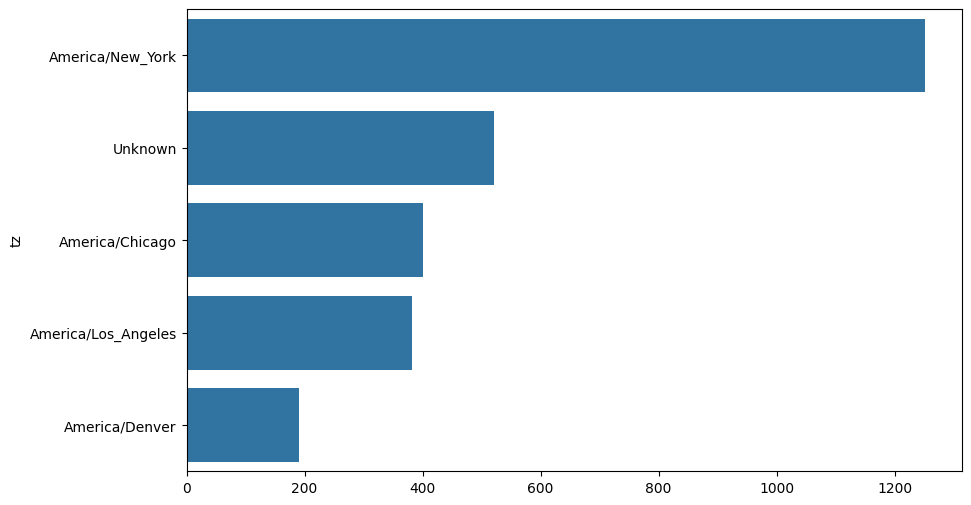

In [ ]:
import seaborn as sns
subset = tz_counts.head()
sns.barplot(y=subset.index, x=subset.to_numpy())

In [ ]:
frame["a"][1]
frame["a"][50]
frame["a"][51][:50]  # long line

'GoogleMaps/RochesterNY'

'Mozilla/5.0 (Windows NT 5.1; rv:10.0.2) Gecko/20100101 Firefox/10.0.2'

'Mozilla/5.0 (Linux; U; Android 2.2.2; en-us; LG-P9'

In [ ]:
results = pd.Series([x.split()[0] for x in frame["a"].dropna()])
results.head(5)
results.value_counts().head(8)

,0
0,Mozilla/5.0
1,GoogleMaps/RochesterNY
2,Mozilla/4.0
3,Mozilla/5.0
4,Mozilla/5.0


,count
Mozilla/5.0,2594
Mozilla/4.0,601
GoogleMaps/RochesterNY,121
Opera/9.80,34
TEST_INTERNET_AGENT,24
GoogleProducer,21
Mozilla/6.0,5
BlackBerry8520/5.0.0.681,4


In [ ]:
cframe = frame[frame["a"].notna()].copy()

In [ ]:
cframe["os"] = np.where(cframe["a"].str.contains("Windows"),
                        "Windows", "Not Windows")
cframe["os"].head(5)

,os
0,Windows
1,Not Windows
2,Windows
3,Not Windows
4,Windows


In [ ]:
by_tz_os = cframe.groupby(["tz", "os"])

In [ ]:
agg_counts = by_tz_os.size().unstack().fillna(0)
agg_counts.head()

os,Not Windows,Windows
tz,,
,245.0,276.0
Africa/Cairo,0.0,3.0
Africa/Casablanca,0.0,1.0
Africa/Ceuta,0.0,2.0
Africa/Johannesburg,0.0,1.0


In [ ]:
indexer = agg_counts.sum("columns").argsort()
indexer.values[:10]

array([ 2,  7,  5,  4, 14, 11,  9,  8, 24, 26])

In [ ]:
count_subset = agg_counts.take(indexer[-10:])
count_subset

os,Not Windows,Windows
tz,,
America/Sao_Paulo,13.0,20.0
Europe/Madrid,16.0,19.0
Pacific/Honolulu,0.0,36.0
Asia/Tokyo,2.0,35.0
Europe/London,43.0,31.0
America/Denver,132.0,59.0
America/Los_Angeles,130.0,252.0
America/Chicago,115.0,285.0
,245.0,276.0


In [ ]:
agg_counts.sum(axis="columns").nlargest(10)

,0
tz,
America/New_York,1251.0
,521.0
America/Chicago,400.0
America/Los_Angeles,382.0
America/Denver,191.0
Europe/London,74.0
Asia/Tokyo,37.0
Pacific/Honolulu,36.0
Europe/Madrid,35.0


,tz,os,total
0,America/Sao_Paulo,Not Windows,13.0
1,America/Sao_Paulo,Windows,20.0
2,Europe/Madrid,Not Windows,16.0
3,Europe/Madrid,Windows,19.0
4,Pacific/Honolulu,Not Windows,0.0
5,Pacific/Honolulu,Windows,36.0
6,Asia/Tokyo,Not Windows,2.0
7,Asia/Tokyo,Windows,35.0
8,Europe/London,Not Windows,43.0
9,Europe/London,Windows,31.0


<Axes: xlabel='total', ylabel='tz'>

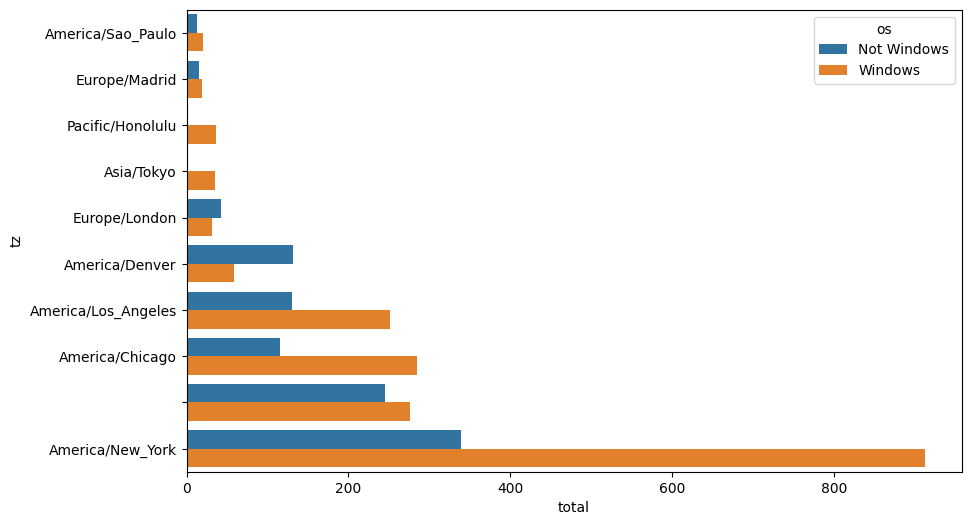

In [ ]:
count_subset = count_subset.stack()
count_subset.name = "total"
count_subset = count_subset.reset_index()
count_subset.head(10)
sns.barplot(x="total", y="tz", hue="os",  data=count_subset)

In [ ]:
def norm_total(group):
    group["normed_total"] = group["total"] / group["total"].sum()
    return group

results = count_subset.groupby("tz").apply(norm_total)

/tmp/ipykernel_3746/1595230757.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results = count_subset.groupby("tz").apply(norm_total)


<Axes: xlabel='normed_total', ylabel='tz'>

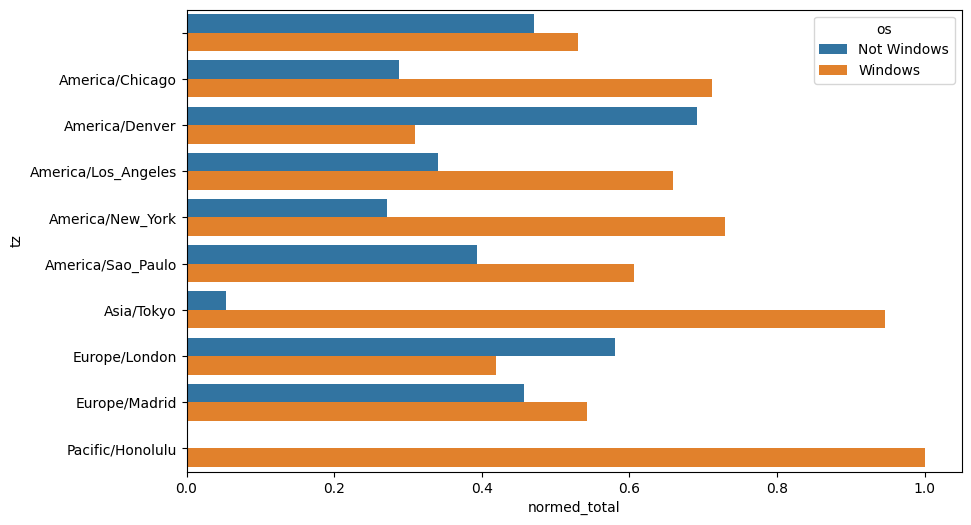

In [ ]:
sns.barplot(x="normed_total", y="tz", hue="os",  data=results)

In [ ]:
g = count_subset.groupby("tz")
results2 = count_subset["total"] / g["total"].transform("sum")
results2

,total
0,0.393939
1,0.606061
2,0.457143
3,0.542857
4,0.000000
5,1.000000
6,0.054054
7,0.945946
8,0.581081
9,0.418919


### **위경도로 시각화**

In [ ]:
frame.head()

,a,c,nk,tz,gr,g,h,l,al,hh,r,u,t,hc,cy,ll,_heartbeat_,kw
0,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) C...",US,1.0,America/New_York,MA,A6qOVH,wfLQtf,orofrog,"en-US,en;q=0.8",1.usa.gov,http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/wfLQtf,http://www.ncbi.nlm.nih.gov/pubmed/22415991,1.331923e+09,1.331823e+09,Danvers,"[42.576698, -70.954903]",NaN,NaN
1,GoogleMaps/RochesterNY,US,0.0,America/Denver,UT,mwszkS,mwszkS,bitly,NaN,j.mp,http://www.AwareMap.com/,http://www.monroecounty.gov/etc/911/rss.php,1.331923e+09,1.308262e+09,Provo,"[40.218102, -111.613297]",NaN,NaN
2,Mozilla/4.0 (compatible; MSIE 8.0; Windows NT 6.1; WOW64; Trident/4.0; SLCC2...,US,1.0,America/New_York,DC,xxr3Qb,xxr3Qb,bitly,en-US,1.usa.gov,http://t.co/03elZC4Q,http://boxer.senate.gov/en/press/releases/031612.cfm,1.331923e+09,1.331920e+09,Washington,"[38.9007, -77.043098]",NaN,NaN
3,"Mozilla/5.0 (Macintosh; Intel Mac OS X 10_6_8) AppleWebKit/534.52.7 (KHTML, ...",BR,0.0,America/Sao_Paulo,27,zCaLwp,zUtuOu,alelex88,pt-br,1.usa.gov,direct,http://apod.nasa.gov/apod/ap120312.html,1.331923e+09,1.331923e+09,Braz,"[-23.549999, -46.616699]",NaN,NaN
4,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) C...",US,0.0,America/New_York,MA,9b6kNl,9b6kNl,bitly,"en-US,en;q=0.8",bit.ly,http://www.shrewsbury-ma.gov/selco/,http://www.shrewsbury-ma.gov/egov/gallery/134127368672998.png,1.331923e+09,1.273672e+09,Shrewsbury,"[42.286499, -71.714699]",NaN,NaN


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

Text(0.5, 1.0, 'Bitly Click Locations by Coordinates')

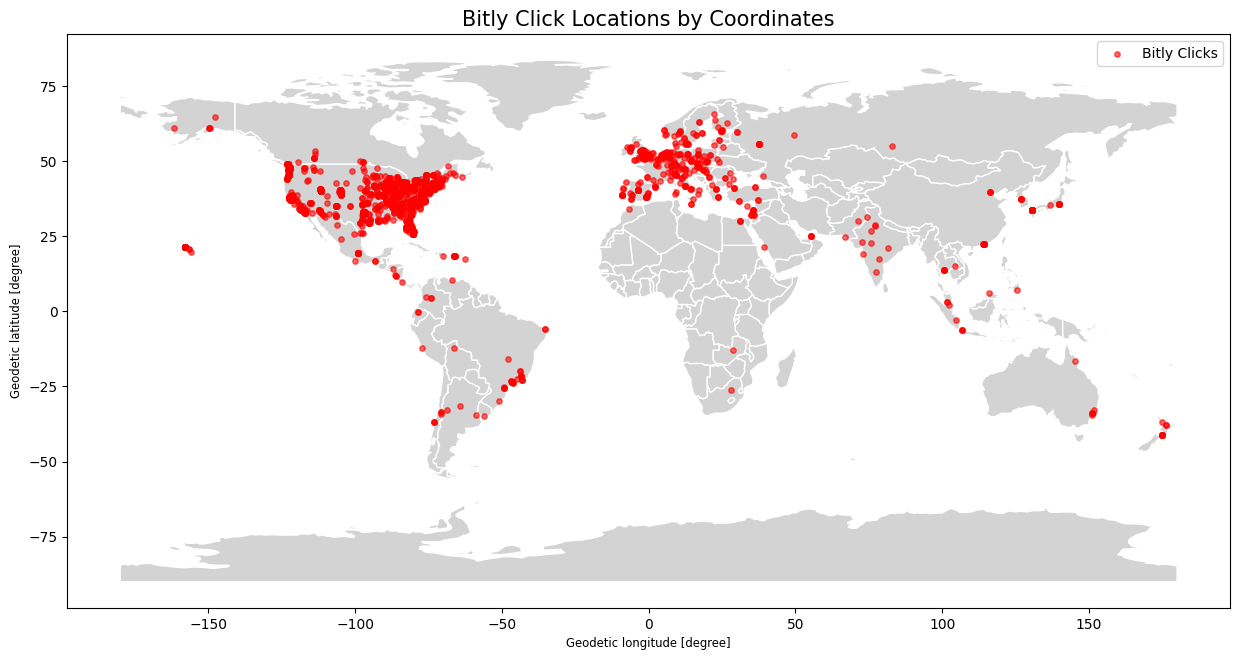

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# 1. ll 컬럼이 유효한(NaN이 아닌) 데이터만 추출합니다.
geo_data = frame[frame['ll'].notna()].copy()

# 2. ll 컬럼([위도, 경도])에서 위도(latitude)와 경도(longitude)를 분리합니다.
geo_data['latitude'] = geo_data['ll'].apply(lambda x: x[0])
geo_data['longitude'] = geo_data['ll'].apply(lambda x: x[1])

# 3. 위경도 데이터를 바탕으로 Shapely Point 객체를 생성합니다.
geometry = [Point(xy) for xy in zip(geo_data['longitude'], geo_data['latitude'])]

# 4. GeoDataFrame으로 변환합니다 (좌표계는 기본 GPS 좌표계인 WGS84 - EPSG:4326 사용)
gdf = gpd.GeoDataFrame(geo_data, geometry=geometry, crs="EPSG:4326")

# 5. Geopandas 내장 데이터 대신, 웹상의 공개 대안 GeoJSON URL을 사용하여 세계 지도를 가져옵니다.
world_url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
world = gpd.read_file(world_url)

fig, ax = plt.subplots(figsize=(15, 8))
world.plot(ax=ax, color='lightgray', edgecolor='white')

# 점들을 지도 위에 플롯팅
gdf.plot(ax=ax, color='red', markersize=15, alpha=0.6, label='Bitly Clicks')

plt.title("Bitly Click Locations by Coordinates", fontsize=15)
plt.legend()
plt.show()